# Coffee Sales: Exploratory Data Analysis

**Team:** TEAM15
**Team members:** Chen, Junxian; Yu, Boyan; Bai, Yuning; Qian, Hongyi.  
**Purpose:** Help a coffee vending-machine operations manager review demand, adjust the mix of ingredient replenishment, and investigate unusual transaction declines.

Source: [Coffee Sales by ihelon (Yaroslav Isaienkov), Kaggle](https://www.kaggle.com/datasets/ihelon/coffee-sales). The author describes real vending-machine sales. We use only `index_1.csv` (machine 1), with one recorded transaction per row. The dataset page identifies the currency as Ukrainian hryvnias (UAH) and the license as CC0. This is a historical snapshot, not a live feed.

Place this notebook beside `index_1.csv`. Select your existing Python environment with Pandas and Matplotlib, then run all cells. No rows are sampled or dropped. The notes below refer to the checked snapshot from 2024-03-01 through 2025-03-23; revise them if you use a different dataset version.

## 1. Load the data and inspect its structure

Check the number of rows, columns, original types, and a few records. The anonymous card identifier is excluded from the preview because our decision does not require customer-level details.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("index_1.csv")
print("Shape:", df.shape)
print("\nOriginal data types:")
print(df.dtypes)
print("\nFirst five transactions (card identifier omitted):")
print(df.drop(columns="card").head().to_string(index=False))

Shape: (3636, 6)

Original data types:
date               str
datetime           str
cash_type          str
card               str
money          float64
coffee_name        str
dtype: object

First five transactions (card identifier omitted):
      date                datetime cash_type  money   coffee_name
2024-03-01 2024-03-01 10:15:50.520      card   38.7         Latte
2024-03-01 2024-03-01 12:19:22.539      card   38.7 Hot Chocolate
2024-03-01 2024-03-01 12:20:18.089      card   38.7 Hot Chocolate
2024-03-01 2024-03-01 13:46:33.006      card   28.9     Americano
2024-03-01 2024-03-01 13:48:14.626      card   38.7         Latte


## 2. Check missing values, duplicates, and amounts

Inspect missing values before deciding whether to remove any data. Missing card identifiers may be normal for cash payments. Preserve every legitimate transaction when counting demand.

In [2]:
print("Missing values:")
print(df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())
print("\nMissing card identifiers by payment method:")
print(pd.crosstab(df["cash_type"], df["card"].isna()))

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["money"] = pd.to_numeric(df["money"], errors="coerce")
print("\nUnusable dates:", df["date"].isna().sum())
print("Unusable amounts:", df["money"].isna().sum())
print("Nonpositive amounts:", (df["money"] <= 0).sum())
print("\nTransaction amounts (UAH):")
print(df["money"].describe().round(2))

Missing values:
date            0
datetime        0
cash_type       0
card           89
money           0
coffee_name     0
dtype: int64

Exact duplicate rows: 0

Missing card identifiers by payment method:
card       False  True 
cash_type              
card        3547      0
cash           0     89

Unusable dates: 0
Unusable amounts: 0
Nonpositive amounts: 0

Transaction amounts (UAH):
count    3636.00
mean       31.75
std         4.92
min        18.12
25%        27.92
50%        32.82
75%        35.76
max        40.00
Name: money, dtype: float64


**Finding and decision:** The snapshot has 3,636 rows and 6 columns, with no exact duplicate rows, invalid dates, invalid amounts, or nonpositive amounts. Only `card` has missing values: all 89 missing identifiers correspond to cash payments. Keep these rows. Dropping them would undercount transactions and revenue. Recorded amounts range from UAH 18.12 to UAH 40.00; there is no obviously extreme amount that justifies deleting a row.

## 3. Check time coverage

A date without records could indicate no sales, a closed/unavailable machine, or missing logging. The CSV cannot distinguish these explanations. Keep those dates unknown rather than filling them with zero.

In [3]:
start = df["date"].min()
end = df["date"].max()
calendar = pd.date_range(start, end, freq="D")
missing_dates = calendar.difference(df["date"].unique())

print("Period:", start.date(), "to", end.date())
print("Calendar days:", len(calendar))
print("Dates with records:", df["date"].nunique())
print("Dates without records:", len(missing_dates))
print(missing_dates.strftime("%Y-%m-%d").tolist())

monthly = df.groupby(df["date"].dt.to_period("M")).size()
print("\nRecorded transactions by month:")
print(monthly.to_string())

Period: 2024-03-01 to 2025-03-23
Calendar days: 388
Dates with records: 381
Dates without records: 7
['2024-05-01', '2024-05-04', '2024-05-05', '2024-11-27', '2025-01-01', '2025-01-19', '2025-01-23']

Recorded transactions by month:
date
2024-03    206
2024-04    196
2024-05    267
2024-06    227
2024-07    237
2024-08    272
2024-09    344
2024-10    426
2024-11    259
2024-12    259
2025-01    201
2025-02    423
2025-03    319
Freq: M


**Finding and decision:** The data runs from 2024-03-01 through 2025-03-23. Seven dates inside this interval have no records. March 2025 stops on the 23rd, so its total must not be compared directly with a full month. The dashboard will label the snapshot period, show gaps in the daily trend, and use a date filter. In production, check feed completeness before treating a decline as a demand change.

## 4. Calculate candidate headline metrics and drink demand

**Transactions** is the primary KPI because the manager needs a measure of recorded purchase activity that does not directly change when prices change. It is not a count of unique customers or a verified quantity of cups. Revenue and average transaction amount help distinguish changes in transaction count from changes in the amount paid per transaction.

In [4]:
transactions = len(df)
revenue = df["money"].sum()
average_amount = df["money"].mean()
print(f"Transactions: {transactions:,}")
print(f"Revenue: UAH {revenue:,.2f}")
print(f"Average transaction amount: UAH {average_amount:.2f}")

drink_summary = df.groupby("coffee_name").agg(
    transactions=("money", "size"),
    revenue=("money", "sum"),
    average_amount=("money", "mean")
).sort_values("transactions", ascending=False)
drink_summary["share_pct"] = drink_summary["transactions"] / transactions * 100
print("\nDrink summary:")
print(drink_summary.round(2).to_string())

Transactions: 3,636
Revenue: UAH 115,431.58
Average transaction amount: UAH 31.75

Drink summary:
                     transactions   revenue  average_amount  share_pct
coffee_name                                                           
Americano with Milk           824  25269.12           30.67      22.66
Latte                         782  27866.30           35.63      21.51
Americano                     578  15062.26           26.06      15.90
Cappuccino                    501  18034.14           36.00      13.78
Cortado                       292   7534.86           25.80       8.03
Hot Chocolate                 282  10172.46           36.07       7.76
Cocoa                         243   8678.16           35.71       6.68
Espresso                      134   2814.28           21.00       3.69


**Finding and decision:** Total recorded revenue is UAH 115,431.58 and the average transaction amount is UAH 31.75. Americano with Milk has 824 transactions and Latte has 782. Together they account for 44.2% of transactions. This supports a compact drink-demand chart for replenishment discussions. These are whole-snapshot findings, not a claim that the same mix applies to every week. Actual ingredient quantities also require recipes, stock levels, and delivery information.

## 5. Inspect distributions and relationships

This EDA may contain more plots than the final dashboard. The amount histogram checks the data and helps interpret the average; it does not need to occupy dashboard space.

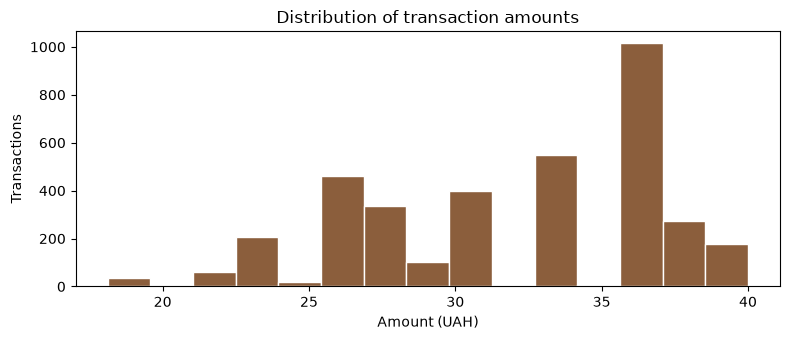

Amount by drink (UAH):
                       min   max   mean
coffee_name                            
Americano            23.02  30.0  26.06
Americano with Milk  27.92  35.0  30.67
Cappuccino           32.82  40.0  36.00
Cocoa                32.82  40.0  35.71
Cortado              23.02  30.0  25.80
Espresso             18.12  25.0  21.00
Hot Chocolate        32.82  40.0  36.07
Latte                32.82  40.0  35.63


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df["money"], bins=15, color="#8B5E3C", edgecolor="white")
ax.set(title="Distribution of transaction amounts", xlabel="Amount (UAH)", ylabel="Transactions")
fig.tight_layout()
plt.show()

print("Amount by drink (UAH):")
print(df.groupby("coffee_name")["money"].agg(["min", "max", "mean"]).round(2).to_string())

**Interpretation:** Transaction amounts differ both across drink categories and within a category. The CSV does not establish whether within-category changes reflect price revisions, discounts, or another cause. Revenue alone therefore cannot measure demand reliably. Keep transaction count first and interpret average transaction amount alongside the drink mix. Do not infer profit because cost data is absent.

## 6. Test the two supporting dashboard charts

The daily transaction trend shows when recorded demand changes. The drink breakdown shows how that demand is distributed. Together they support investigation and replenishment planning without adding unrelated charts.

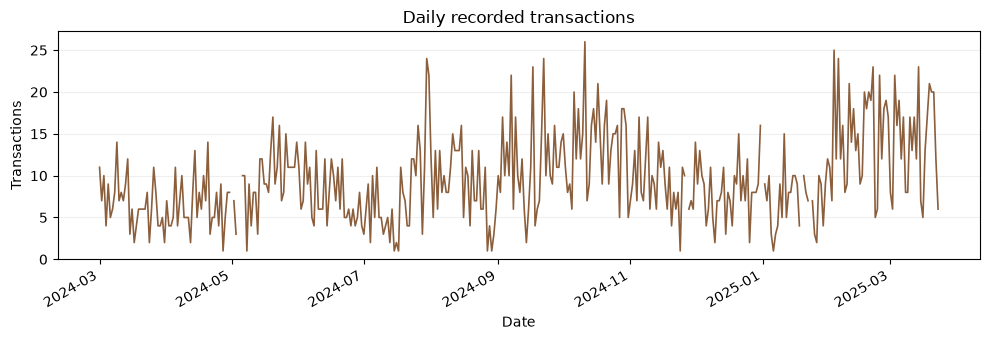

Gaps represent dates without records; no zero sales values are imputed.


In [6]:
daily = df.groupby("date").size().reindex(calendar)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(daily.index, daily.values, color="#8B5E3C", linewidth=1.2)
ax.set(title="Daily recorded transactions", xlabel="Date", ylabel="Transactions")
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.2)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
print("Gaps represent dates without records; no zero sales values are imputed.")

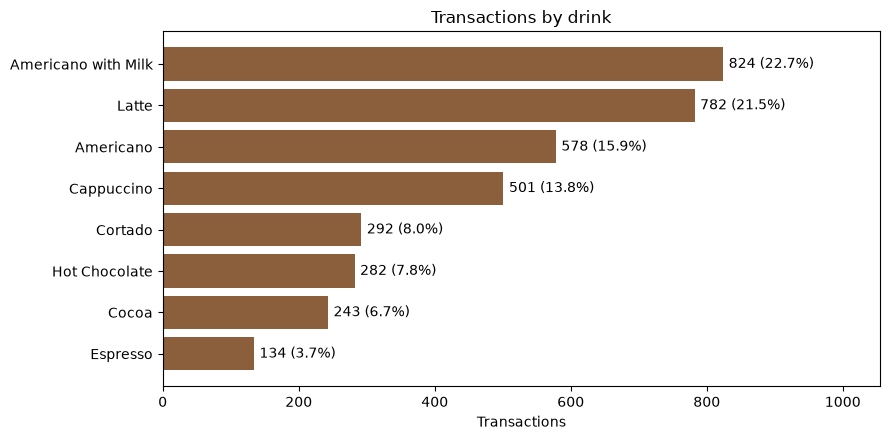

In [7]:
plot_data = drink_summary.sort_values("transactions")
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(plot_data.index, plot_data["transactions"], color="#8B5E3C")
labels = [f"{n:,} ({s:.1f}%)" for n, s in zip(plot_data["transactions"], plot_data["share_pct"])]
ax.bar_label(bars, labels=labels, padding=4)
ax.set(title="Transactions by drink", xlabel="Transactions", ylabel="")
ax.set_xlim(0, plot_data["transactions"].max() * 1.28)
fig.tight_layout()
plt.show()

## 7. Decisions for the planned dashboard

- **Audience and action:** One coffee vending-machine operations manager. Review anomalies each morning and ingredient mix each week. A sustained shift toward a drink prompts a review of its ingredient allocation; an unusual decline prompts an on-site/data check.
- **Headline KPIs (three):** Transaction count first, sales revenue (UAH), and average transaction amount (UAH).
- **Supporting charts (two):** Daily transaction count and transactions by drink with percentage shares. Filter both charts and the KPIs by the same date range.
- **Cut:** Anonymous card identifiers and payment-method distribution. Neither changes the chosen replenishment decision. The amount histogram stays in this notebook only. No raw-transaction table is planned because routine review does not require it.
- **Order:** Team title and audience caption, then the three KPIs, then the two explanatory charts. A date filter sits in the sidebar. Clearly visible captions state the snapshot period, production refresh plan, and missing-data limitation.
- **Production refresh:** Nightly after transactions are reconciled. Review the next morning; revise the replenishment mix weekly. Minute-by-minute refresh would add effort without changing the weekly ordering schedule. Immediate equipment faults should use a separate operational alert.
- **Proposed action rule:** If the latest complete Monday-Sunday week has over 20% fewer transactions than the previous complete week, verify logging and known closures, then contact the on-site operator if unexplained. A calendar-complete week does not guarantee a complete data feed. The 20% threshold is a proposed business assumption, not a validated model or measured fault probability.
- **Stale-data cost:** A day's delay can postpone anomaly checks; a week's delay can leave replenishment based on an outdated drink mix.

The proposed workflow is a classroom business scenario, not evidence from an interview with the dataset owner. See `README.md` for the written justification. Draw the planned page on paper before implementing the Streamlit app.